# ¿Coincide el wrapper con su referencia y qué no demuestra?

**Pregunta:** ¿CrossGradient del producto reproduce SimPEG fijado con entradas idénticas, y dónde termina la comparación?

**Nivel 3 — comparación con los mismos datos**  
**Prerrequisitos:** objetivo conjunto, mallas tensoriales, celdas activas y paridad numérica; 40 min.

## Objetivos

Ejecutar wrapper y CrossGradient de SimPEG con el mismo plan, celdas activas, vectores, escalas y longitud de acoplamiento. Comparar objetivo y derivadas, separando paridad de software de convergencia, predicción y validez de campo.

## Preparación

Instale las dependencias exactas:

```bash
pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8 simpeg==0.25.2 discretize==0.12.0
```

Ambas implementaciones reciben el mismo control diseñado de doce celdas; el plan y orden de modelos se fijan antes de calcular.

## Datos

La entrada compartida es un control determinista local diseñado con doce celdas activas, geometría receptora gravimétrica y magnética, vectores acotados y metadatos de incertidumbre. No contiene observaciones de campo. Wrapper y referencia usan los mismos arreglos para que la comparación pruebe implementación numérica y no selección de datos.

## Método

El gradiente cruzado penaliza orientaciones discordantes de gradientes de propiedades. Las entradas idénticas permiten atribuir diferencias al adaptador o convenciones, no a selección de datos. Se comparan objetivo, gradiente y producto Hessiano-vectorial. Es una prueba acotada de paridad sobre una malla y parametrización, no un benchmark de inversiones independientes: ambas llamadas evalúan el mismo prior y ninguna ajusta datos observados.

Una comparación pertinente nombra implementación y versión, alinea discretización y unidades, usa entradas idénticas y explica lo no probado. Esta comparación cumple esos puntos para SimPEG. No evalúa priors alternativos, optimizadores ni resultados de campo. Puede existir concordancia exacta junto con resolución baja, modelos no únicos, hipótesis estructural falsa o mala predicción reservada.


In [1]:
# Importe el evaluador físico fijado y muestre las versiones del entorno.
from pathlib import Path
import sys
from importlib.metadata import version
import numpy as np
import matplotlib.pyplot as plt

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline/joint_survey_structure.py").is_file()
)
sys.path.insert(0, str(root / "data-pipeline"))
import joint_survey_plan as planner
import joint_survey_structure as physical_structure

print("NumPy", version("numpy"), "SimPEG", version("simpeg"), "discretize", version("discretize"))


NumPy 2.2.6 SimPEG 0.25.2 discretize 0.12.0


### Control diseñado compartido

El control de doce celdas fija metadatos, límites y escalas, además de geometría determinista. Proporciona entradas precisas para comparar. Densidad y susceptibilidad son prescritas, no estimadas, así que la prueba no dice qué respalda un sondeo real. Las entradas idénticas evitan atribuir a implementación diferencias debidas a máscaras, orden de vectores o unidades.


In [2]:
# Defina un control ENU pequeño de creación propia y sus escalas físicas declaradas.
receivers = np.array(
    [20, 30, 100, 50, 80, 110, -90, 40, 130, 10, -10, 150, 90, -50, 120, 130, 40, 160], dtype=float
).reshape(6, 3)
mag_receivers = receivers + [5, 0, 0]
src = dict(
    citation="Authored numerical control, not field data",
    raw_bytes=123,
    rights="private_use",
    correction_sha256="c" * 64,
)
g_source = dict(src, source_id="gravity", raw_sha256="a" * 64)
m_source = dict(src, source_id="magnetic", raw_sha256="b" * 64)
noise = dict(basis="measured_gaussian", cross_partition="declared_absent", citation="Authored error control")
noise_g = dict(noise, kind="diagonal_sd", unit="mGal")
noise_m = dict(noise, kind="diagonal_sd", unit="nT")
common = dict(reference_id="authored-local-enu", mask=np.zeros(6, bool), missing_reasons=("",) * 6)
common.update(groups=np.array([0, 0, 1, 1, 2, 2]), partition=np.array([0, 0, 1, 1, 2, 2]))
gravity = dict(common, source=g_source, component="gz_up", unit="mGal", receivers_m=receivers, noise=noise_g)
field = dict(amplitude_nt=50000.0, inclination_deg=60.0, declination_deg=12.0)


### Marco de adquisición e incertidumbre

Las coordenadas gravimétricas y magnéticas comparten ENU local, pero receptores magnéticos están desplazados y las unidades difieren. Errores gaussianos independientes describen la solicitud sintética; no se invierten mediciones ni realizaciones de ruido. Covarianza, topografía, remanencia y transformación de coordenadas requieren validación aparte.


In [3]:
# Conserve escalas y orden de malla declarados: ambos intervienen en la derivada discreta.
magnetic = dict(
    common,
    source=m_source,
    component="linear_tmi",
    unit="nT",
    receivers_m=mag_receivers,
    noise=noise_m,
    inducing_field=field,
)
density = dict(
    lower=np.full(12, -1500.0),
    upper=np.full(12, 1500.0),
    start=np.zeros(12),
    reference=np.zeros(12),
    scale=750.0,
)
susceptibility = dict(
    lower=np.zeros(12),
    upper=np.full(12, 0.1),
    start=np.full(12, 0.005),
    reference=np.full(12, 0.005),
    scale=0.03,
)


### Contrato de malla y parámetros

Malla tensorial, máscara activa, orden x-fast y escalas definen la referencia. Ambas implementaciones deben compartirlas para que la paridad sea válida. Una permutación puede conservar norma y cambiar valores locales; distintas escalas parecen defectos. El control cubre una topología compacta, no cualquier malla o tratamiento de bordes.


In [4]:
# Conserve escalas y orden de malla declarados: ambos intervienen en la derivada discreta.
frame = dict(
    kind="local_cartesian",
    axes=("east", "north", "up"),
    length_unit="m",
    vertical_positive="up",
    reference_id="authored-local-enu",
)
frame.update(horizontal_datum="declared local origin", vertical_datum="declared elevation datum")
mesh = dict(
    origin_m=np.array([-140.0, -180.0, -260.0]),
    hx_m=np.array([40.0, 70.0, 90.0]),
    hy_m=np.array([30.0, 50.0]),
    hz_m=np.array([60.0, 110.0]),
    active=np.ones(12, bool),
)
prior = dict(
    density=density,
    susceptibility=susceptibility,
    lengths_m=np.array([60.0, 110.0, 75.0]),
    coupling_length_m=100.0,
    basis="Declared physical scales",
)


### Plan antes de la referencia

El planificador valida y normaliza entradas del wrapper. El mismo plan proporciona malla y soporte a la llamada de SimPEG, explicitando orden y escala. Sigue siendo control del contrato de software, no prueba de realismo geológico ni de pertinencia del prior.


In [5]:
# Valide unidades, celdas activas y grupos antes de evaluar la cantidad estructural conjunta.
policy = dict(
    name="joint-survey-l2-cross-gradient-1", seed=42, cell_order="x-fast", training="not_applicable_classical"
)
policy.update(group_scope="global_acquisition", modal_covariance="independent")
physical_request = dict(
    schema="joint-survey-plan-request-1",
    frame=frame,
    mesh=mesh,
    gravity=gravity,
    magnetic=magnetic,
    prior=prior,
    policy=policy,
)
physical_plan = planner.plan_joint_survey(physical_request)
physical_n = 12
physical_rho, physical_chi = np.linspace(-400.0, 500.0, 12), np.linspace(0.004, 0.045, 12) + 0.002 * np.sin(
    np.arange(12)
)
physical_direction = np.sin(np.arange(24) + 0.3) / np.linalg.norm(np.sin(np.arange(24) + 0.3))
print("celdas activas creadas", int(physical_plan["mesh"]["active"].sum()), "número de receptores", len(receivers))


celdas activas creadas 12 número de receptores 6


### Paso 1 — evaluar wrapper del producto

Conserve objetivo, gradiente y producto Hessiano-vectorial para el par fijo. No se actualizan propiedades ni se minimizan residuos. La huella del plan registra el contrato preciso que recibirá la referencia.


In [6]:
# Ejecute el wrapper del producto sobre el control físico.
r = physical_structure.evaluate_joint_structure(
    {
        "schema": "joint-survey-structure-request-1",
        "survey_request": physical_request,
        "density_kg_m3": physical_rho,
        "susceptibility_si": physical_chi,
        "direction_physical": physical_direction,
    }
)
print("objetivo del producto", r['objective'], "plan", r["plan_sha256"])


objetivo del producto 0.012770248999752326 plan c62903164d0f129d95137ffe16f334e3cf0d936d26f1f8fa04c6d4da3da9563c


### Paso 2 — construir malla de referencia

Genere malla y máscara activa de SimPEG desde el plan normalizado. Confirme celdas y orden idénticos para ambas propiedades. Una permutación puede preservar la norma y alterar resultados locales; diferencias de escala también imitan fallas de implementación.


In [7]:
# Vuelva a ejecutar el planificador público antes de construir la referencia independiente de SimPEG.
physical_plan_check = planner.plan_joint_survey(physical_request)
assert physical_plan_check["plan_sha256"] == physical_plan["plan_sha256"]
from discretize import TensorMesh
from simpeg import maps
from simpeg.regularization import CrossGradient

mesh = TensorMesh(
    [physical_plan_check["mesh"][k] for k in ("hx_m", "hy_m", "hz_m")],
    origin=physical_plan_check["mesh"]["origin_m"],
)
print("celdas tensoriales del mismo plan", mesh.nC)


celdas tensoriales del mismo plan 12


### Paso 3 — ejecutar CrossGradient fijado

Evalúe SimPEG con los mismos vectores, escalas y longitud. Es otra ruta de software, no experimento físico independiente: comparte entradas e hipótesis. Interprete como paridad de este contrato.


In [8]:
# Calcule el objetivo de referencia con las mismas escalas y máscara activa.
wires = maps.Wires(("density", physical_n), ("susceptibility", physical_n))
ref = CrossGradient(mesh, wires, active_cells=physical_plan["mesh"]["active"], approx_hessian=False)
scales = np.r_[
    np.full(physical_n, physical_plan["prior"]["density"]["scale"]),
    np.full(physical_n, physical_plan["prior"]["susceptibility"]["scale"]),
]
x = np.r_[physical_rho, physical_chi] / scales
vol = mesh.cell_volumes[physical_plan["mesh"]["active"]]
factor = physical_plan["prior"]["coupling_length_m"] ** 4 / float(vol.sum())
reference_value = float(factor * ref(x))
print("objetivo SimPEG directo", reference_value)


objetivo SimPEG directo 0.012770248999752326


### Paso 4 — comparar objetivo y derivadas

Compare escalar, gradiente completo y componentes Hessiano-vectoriales. Coincidir a precisión mostrada ejercita más que un único escalar, pero cubre un punto, dirección y discretización. No establece equivalencia global ni comportamiento del optimizador en otra malla.


In [9]:
# Recalcule la acción Hessiana del wrapper con la dirección física invertida.
reverse_result = physical_structure.evaluate_joint_structure(
    {
        "schema": "joint-survey-structure-request-1",
        "survey_request": physical_request,
        "density_kg_m3": physical_rho,
        "susceptibility_si": physical_chi,
        "direction_physical": -physical_direction,
    }
)
reverse_hv = np.asarray(reverse_result["exact_hessian_vector_physical"])
g = np.asarray(factor * ref.deriv(x) / scales)
hv = np.asarray(factor * ref.deriv2(x, physical_direction / scales) / scales)
print("diferencia absoluta del objetivo", abs(reference_value - r['objective']))
print("diferencia máxima del gradiente", np.max(np.abs(g - r["gradient_physical"])))
print("diferencia máxima del producto Hessiano-vector", np.max(np.abs(hv - r["exact_hessian_vector_physical"])))
print("diferencia máxima por inversión de dirección", np.max(np.abs(reverse_hv + r["exact_hessian_vector_physical"])))


diferencia absoluta del objetivo 0.0
diferencia máxima del gradiente 0.0
diferencia máxima del producto Hessiano-vector 0.0
diferencia máxima por inversión de dirección 0.0


### Paso 5 — conservar vista por celda

Inspeccione aportes por celda junto a la paridad agregada. Valores locales pueden revelar errores de índice ocultos en un escalar. No son sección, residuo, medida de resolución ni estimación de contacto. Informe el diagnóstico junto con sus límites.


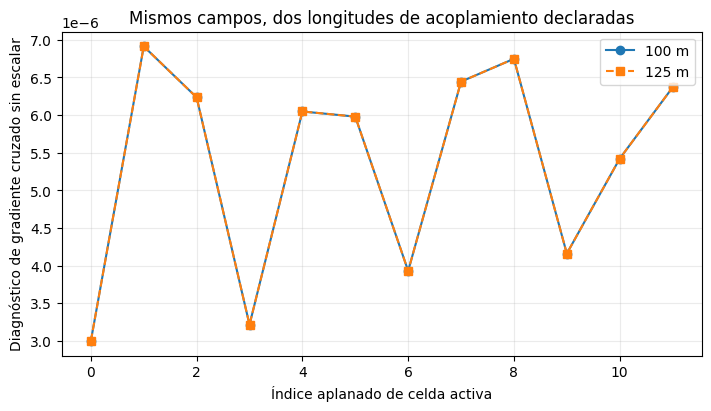

objetivo de referencia y perturbado 0.012770248999752326 0.031177365722051577


In [10]:
# Evalúe una perturbación de longitud del 25 % con los campos de propiedades sin cambios.
from copy import deepcopy

length_request = deepcopy(physical_request)
length_request["prior"]["coupling_length_m"] *= 1.25
length_result = physical_structure.evaluate_joint_structure(
    {
        "schema": "joint-survey-structure-request-1",
        "survey_request": length_request,
        "density_kg_m3": physical_rho,
        "susceptibility_si": physical_chi,
        "direction_physical": physical_direction,
    }
)
d = np.asarray(r["cell_centre_cross_gradient"])
d_length = np.asarray(length_result["cell_centre_cross_gradient"])
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.plot(np.arange(len(d)), d, "o-", label="100 m")
ax.plot(np.arange(len(d_length)), d_length, "s--", label="125 m")
ax.set(
    xlabel="Índice aplanado de celda activa",
    ylabel="Diagnóstico de gradiente cruzado sin escalar",
    title="Mismos campos, dos longitudes de acoplamiento declaradas",
)
ax.legend()
ax.grid(alpha=0.25)
plt.show()
print("objetivo de referencia y perturbado", r['objective'], length_result['objective'])


La figura informa valores recalculados para el control diseñado. Los ejes muestran concordancia numérica, no ajuste de observaciones. Los modelos son prescritos y no se invierte. La figura respalda una afirmación acotada de implementación; deja sin responder resolución, incertidumbre y predicción.


## Comparación

CrossGradient de SimPEG es un regularizador estructural publicado en un marco abierto de inversión geofísica. Su llamada directa fijada es una referencia pertinente. Compartir malla planificada, celdas, vectores, escalas y longitud controla fuentes principales de discrepancia. El tutorial de SimPEG contextualiza el método; no valida independientemente este producto ni el control presente.

La prueba no demuestra superioridad frente a inversiones independientes, acoplamiento petrofísico u otro prior. Tampoco unicidad. El término puede ser débil donde una propiedad es plana e insensible a algunas diferencias de amplitud. Gradientes alineados pueden coexistir con baja resolución de una modalidad. Si la estructura común supuesta es falsa, el prior puede transferir un límite plausible que los datos débiles no respaldan.

La paridad es una etapa: contrato, equivalencia numérica, ajuste directo, convergencia y predicción reservada, resolución o incertidumbre y corroboración geológica. Este notebook mide solo paridad. No compara familias independientes de solvers ni afirma preparación para campo.

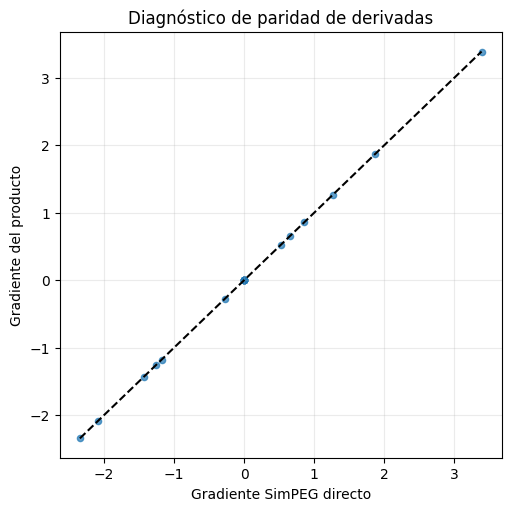

In [11]:
# Compare las componentes del gradiente del producto y de SimPEG directo.
fig, ax = plt.subplots(figsize=(5, 5), constrained_layout=True)
ax.scatter(g, r["gradient_physical"], s=20, alpha=0.7)
lo = min(g.min(), np.min(r["gradient_physical"]))
hi = max(g.max(), np.max(r["gradient_physical"]))
ax.plot([lo, hi], [lo, hi], "k--")
ax.set(xlabel="Gradiente SimPEG directo", ylabel="Gradiente del producto", title="Diagnóstico de paridad de derivadas")
ax.grid(alpha=0.25)
plt.show()


### Interpretación de la figura

Los puntos del wrapper y SimPEG fijado siguen la diagonal; la diferencia máxima registrada es cero a la precisión mostrada. Respalda paridad para la malla, orden y escalas probadas. No cubre toda topología o versión, y no se usaron observaciones. Igualdad de salidas no prueba convergencia, predicción, resolución, unicidad ni validez de la hipótesis estructural.




## Resultados

**Respuesta:** En el control diseñado de doce celdas, las diferencias máximas de objetivo, gradiente y producto Hessiano-vectorial entre wrapper y referencia son cero a la precisión mostrada. Respalda paridad solo para este contrato.

## Resumen

La referencia con entradas idénticas aísla comportamiento de software. Su alcance científico es reducido: no se ajustaron observaciones, no se recuperó modelo y la igualdad no sustenta afirmaciones predictivas o de campo.

## Referencias

- [Tutorial de gradiente cruzado de SimPEG](https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html)
- Cockett et al. (2015), [SimPEG](https://doi.org/10.1016/j.cageo.2015.09.015)
- `data-pipeline/joint_survey_plan.py`; `data-pipeline/joint_survey_structure.py`
